# Algoritmo genético y laberinto

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Este cuaderno contiene una copia completa de `laberinto.py` y sus salidas reales. Ejecuta todas las celdas en orden, desde esta carpeta. La explicación y el análisis están en [README.md](README.md). Los archivos de entrada están en `datos/` cuando corresponda.

El código fuente principal se conserva en el archivo `.py`; `herramientas/generar_cuadernos.py` regenera y ejecuta este cuaderno después de cambiarlo.

In [1]:
import os, sys
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
# Las rutas y argumentos equivalen a ejecutar el script desde esta carpeta.
__file__ = str(Path.cwd() / 'laberinto.py')
sys.argv = [__file__]

In [2]:
"""Algoritmo genético; BFS aporta distancias para fitness, no cromosomas."""
import csv
import json
import random
from collections import deque
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

MAPA=["###############","#S............#","#############.#","#.............#","#.#############","#.............#","#############.#","#G............#","###############"]
MOV=[(-1,0),(1,0),(0,-1),(0,1)]
INICIO=(1,1); META=(7,1)


def libre(pos):
    r,c=pos; return 0<=r<len(MAPA) and 0<=c<len(MAPA[0]) and MAPA[r][c]!="#"


def distancias():
    d={META:0}; cola=deque([META])
    while cola:
        r,c=cola.popleft()
        for dr,dc in MOV:
            p=(r+dr,c+dc)
            if libre(p) and p not in d: d[p]=d[(r,c)]+1; cola.append(p)
    return d


DIST=distancias()


def simular(genes):
    pos=INICIO; camino=[pos]; invalidos=0
    for paso,g in enumerate(genes,1):
        dr,dc=MOV[g]; siguiente=(pos[0]+dr,pos[1]+dc)
        if libre(siguiente): pos=siguiente; camino.append(pos)
        else: invalidos+=1
        if pos==META: return 10000-10*paso-invalidos,camino,True,paso
    fitness=-10*DIST.get(pos,1000)-.5*invalidos+.1*len(set(camino))
    return fitness,camino,False,len(genes)


def evolucionar():
    rng=random.Random(2430085); n=240; longitud=160; max_gen=500
    poblacion=[[rng.randrange(4) for _ in range(longitud)] for _ in range(n)]
    historial=[]
    for gen in range(max_gen):
        evaluados=sorted([(simular(g)[0],g) for g in poblacion],key=lambda x:x[0],reverse=True)
        historial.append([gen,evaluados[0][0],sum(v for v,g in evaluados)/n])
        mejor=evaluados[0][1]; evaluacion=simular(mejor)
        if gen%10==0 or evaluacion[2]: print(f"Generación {gen}: fitness={evaluados[0][0]:.2f}; meta={evaluacion[2]}",flush=True)
        if evaluacion[2]: return mejor,evaluacion,historial
        nueva=[g[:] for _,g in evaluados[:6]]
        def torneo(): return max(rng.sample(evaluados,5),key=lambda x:x[0])[1]
        while len(nueva)<n:
            padre,madre=torneo(),torneo(); corte=rng.randrange(1,longitud)
            hijo=padre[:corte]+madre[corte:]
            hijo=[rng.randrange(4) if rng.random()<.02 else g for g in hijo]
            nueva.append(hijo)
        poblacion=nueva
    return mejor,evaluacion,historial


def main():
    mejor,evaluacion,historial=evolucionar(); fitness,camino,llego,pasos=evaluacion
    assert all(libre(p) for p in camino)
    assert all(abs(a[0]-b[0])+abs(a[1]-b[1])==1 for a,b in zip(camino,camino[1:]))
    assert llego and camino[-1]==META, "No se encontró la meta en el presupuesto de generaciones."
    out=Path(__file__).parent/"resultados"; out.mkdir(exist_ok=True)
    (out/"solucion.json").write_text(json.dumps({"semilla":2430085,"meta_alcanzada":llego,"generacion":historial[-1][0],"pasos_genes":pasos,"movimientos_validos":len(camino)-1,"distancia_minima_bfs":DIST[INICIO],"fitness":fitness,"genes":mejor[:pasos],"camino":camino},indent=2),encoding="utf-8")
    with (out/"evolucion.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.writer(f); w.writerow(["generacion","mejor_fitness","promedio"]); w.writerows(historial)
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    ax[0].imshow([[int(c=="#") for c in fila] for fila in MAPA],cmap="binary")
    ax[0].plot([p[1] for p in camino],[p[0] for p in camino],"-",color="#e56c33",linewidth=2)
    ax[0].scatter([INICIO[1],META[1]],[INICIO[0],META[0]],c=["green","red"],s=70); ax[0].set_title("Recorrido encontrado por evolución")
    h=np.array(historial); ax[1].plot(h[:,0],h[:,1],label="Mejor"); ax[1].plot(h[:,0],h[:,2],label="Promedio"); ax[1].legend(); ax[1].set(xlabel="Generación",ylabel="Fitness",title="Mejora de la población")
    fig.tight_layout(); fig.savefig(out/"laberinto.png",dpi=150); plt.close(fig)
    print(f"Meta alcanzada en generación {historial[-1][0]}; movimientos válidos={len(camino)-1}; distancia óptima BFS={DIST[INICIO]}.")
    print("BFS solo calculó distancias de evaluación. La secuencia fue producida por selección, cruce y mutación.")


if __name__=="__main__": main()


Generación 0: fitness=-289.40; meta=False


Generación 10: fitness=-217.90; meta=False


Generación 20: fitness=-143.70; meta=False


Generación 30: fitness=-98.30; meta=False


Generación 40: fitness=-54.90; meta=False


Generación 50: fitness=-31.70; meta=False


... (10 outputs left out)

Generación 160: fitness=-8.10; meta=False


Generación 170: fitness=-8.10; meta=False


Generación 172: fitness=8382.00; meta=True


Meta alcanzada en generación 172; movimientos válidos=142; distancia óptima BFS=54.
BFS solo calculó distancias de evaluación. La secuencia fue producida por selección, cruce y mutación.


## Imágenes producidas por esta ejecución

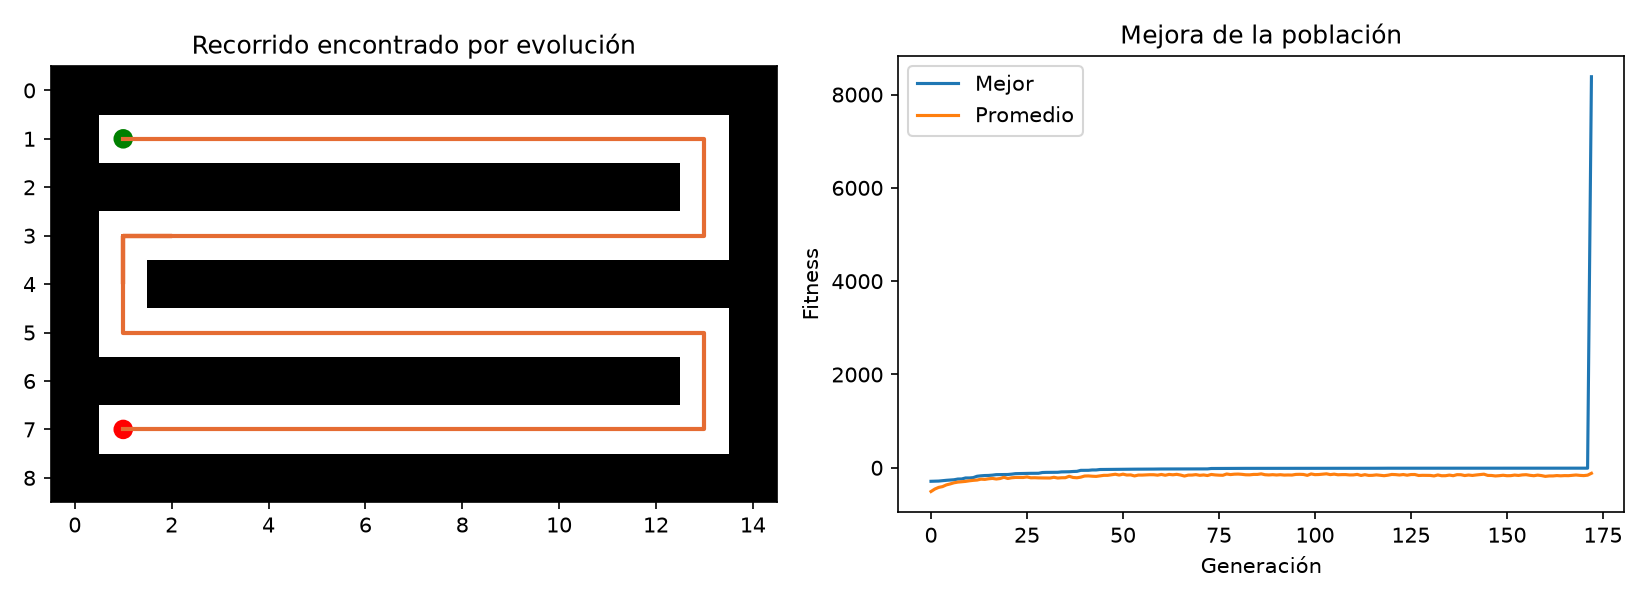

In [3]:
from IPython.display import display, Image
display(Image(filename='resultados/laberinto.png'))